# Experiment 2: Dimensionality Reduction using PCA and LDA
**Aim:** Reduce the number of features using PCA and LDA and observe the effect on model performance and computational efficiency.

**Dataset:** Wine (built into scikit-learn): 178 wine samples, **13 chemical features** (alcohol, malic acid, flavanoids, colour intensity, …), 3 classes (3 grape cultivars).

In [1]:
print("Name    : Pranav Santosh Swami")
print("Roll no : 71")

Name    : Pranav Santosh Swami
Roll no : 71


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings("ignore")

In [3]:
data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Shape of X:", X.shape)
print("Classes:", data.target_names)
print(pd.Series(y).value_counts().sort_index())
X.head()

Shape of X: (178, 13)
Classes: ['class_0' 'class_1' 'class_2']
0    59
1    71
2    48
dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## PCA (unsupervised): keeps the directions with maximum variance. Reduce 13 features to 2

Features after PCA: 2
Variance kept by 2 components: 0.5506


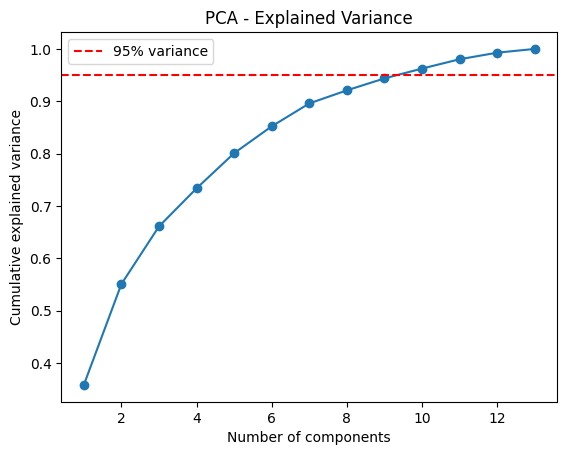

In [5]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
print("Features after PCA:", X_train_pca.shape[1])
print("Variance kept by 2 components:", round(pca.explained_variance_ratio_.sum(), 4))

# cumulative explained variance for all 13 components
pca_full = PCA().fit(X_train)
plt.plot(range(1, 14), np.cumsum(pca_full.explained_variance_ratio_), marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="95% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA - Explained Variance")
plt.legend()
plt.show()

## LDA (supervised): uses class labels to maximise separation between classes. Max components = classes − 1 = 2

In [6]:
lda = LinearDiscriminantAnalysis(n_components=2)
X_train_lda = lda.fit_transform(X_train, y_train)     # LDA needs y (labels), PCA does not
X_test_lda = lda.transform(X_test)
print("Features after LDA:", X_train_lda.shape[1])

Features after LDA: 2


## Compare model performance and training time

In [7]:
feature_sets = {
    "Original": (X_train, X_test),
    "PCA": (X_train_pca, X_test_pca),
    "LDA": (X_train_lda, X_test_lda),
}

results = []
for name, (Xtr, Xte) in feature_sets.items():
    model = LogisticRegression(max_iter=5000)
    start = time.time()
    for _ in range(100):                 # one training is too fast to measure, so train 100 times
        model.fit(Xtr, y_train)
    train_time = time.time() - start
    acc = accuracy_score(y_test, model.predict(Xte))
    results.append([name, Xtr.shape[1], round(acc, 4), round(train_time, 4)])

results = pd.DataFrame(results, columns=["Method", "No. of Features", "Accuracy", "Time for 100 trainings (s)"])
results

,Method,No. of Features,Accuracy,Time for 100 trainings (s)
0,Original,13,0.9722,0.3227
1,PCA,2,0.9167,0.2380
2,LDA,2,0.9722,0.2830


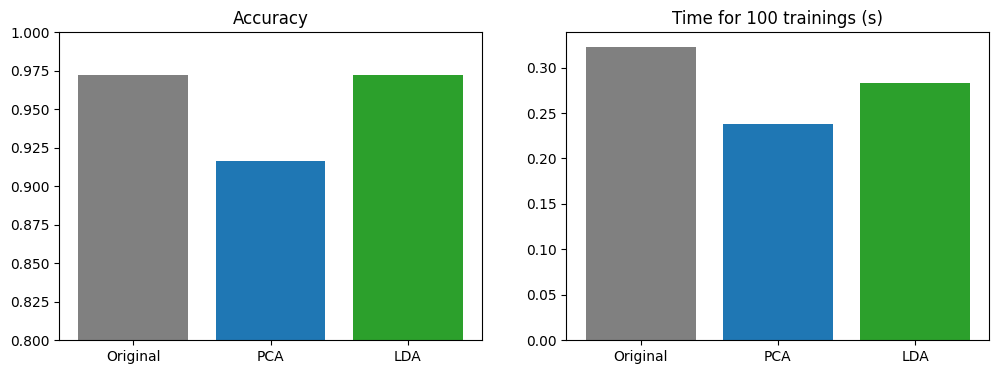

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(results["Method"], results["Accuracy"], color=["gray", "tab:blue", "tab:green"])
ax[0].set_ylim(0.8, 1.0)
ax[0].set_title("Accuracy")
ax[1].bar(results["Method"], results["Time for 100 trainings (s)"], color=["gray", "tab:blue", "tab:green"])
ax[1].set_title("Time for 100 trainings (s)")
plt.show()

## Visualise the 2D data: PCA vs LDA

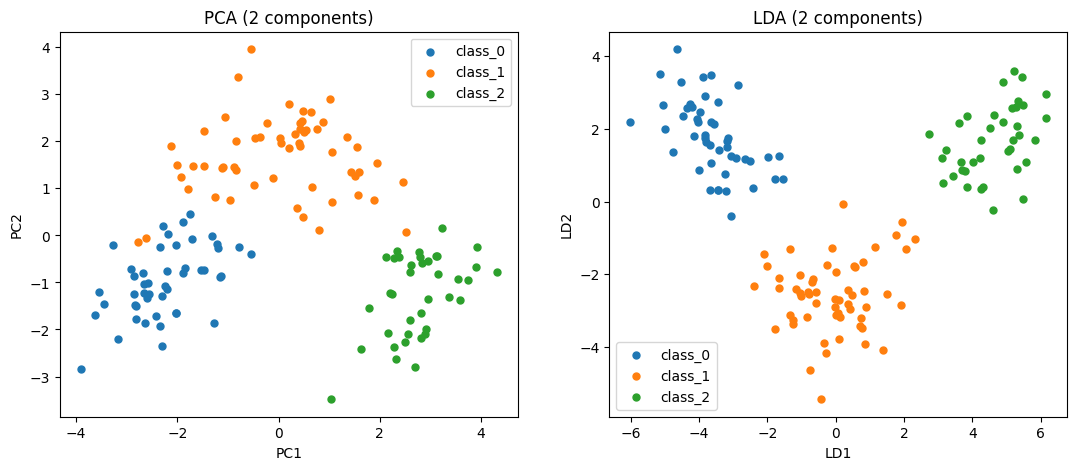

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for cls in range(3):
    ax[0].scatter(X_train_pca[y_train == cls, 0], X_train_pca[y_train == cls, 1], label=data.target_names[cls], s=25)
    ax[1].scatter(X_train_lda[y_train == cls, 0], X_train_lda[y_train == cls, 1], label=data.target_names[cls], s=25)
ax[0].set_title("PCA (2 components)")
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")
ax[1].set_title("LDA (2 components)")
ax[1].set_xlabel("LD1")
ax[1].set_ylabel("LD2")
ax[0].legend()
ax[1].legend()
plt.show()

## Conclusion
Both PCA and LDA reduced the 13 features to just 2.
- **LDA kept the full accuracy (97.2%)** because it uses the class labels to find the directions that best separate the 3 wine classes. In the 2D plot the classes form 3 clearly separate groups.
- **PCA dropped to 91.7%** because its 2 components keep only 55% of the variance and it ignores the labels, so some classes overlap. PCA needs 10 components to keep 95% of the variance.
- With fewer features, training was about 15–25% faster (100 trainings: ~0.32 s original vs ~0.24–0.28 s reduced). The saving is small on a dataset this small, but grows on large datasets. Exact times change a little on every run.